# Notebook 05: Agent-Based Models

**Paper Reference:** Gould et al. (2013), Sections 5.1–5.3

This notebook compares five models:
1. **Smith et al. (2003)** — zero intelligence: independent Poisson order flow, uniform placement
2. **ZI with self-exciting market orders** — the same, except that market orders arrive as a Hawkes process: each one raises the rate of further market orders for a while. Zhao (2010) and Toke (2011) replaced the Poisson processes of another zero-intelligence model, Cont et al. (2010), with Hawkes processes (Section 5.2.4)
3. **Mike & Farmer (2008), simplified** — power-law relative prices measured from the mid-price, long-memory order signs, log-normal sizes, constant-rate cancellation
4. **Mike & Farmer (2008) structure** — prices set relative to the same-side best quote with Student's $t$ offsets (so orders can land inside the spread or cross it), long-memory signs, and state-dependent cancellation
5. **Parlour (1998)-inspired** — a hand-tuned rule in which traders choose between market and limit orders based on the spread and the queue at the best quotes

and measures which stylized facts each one reproduces. Every entry in the scorecard is computed from the simulations, using the criteria stated in Section 4.

In [1]:
import os
import sys
import warnings
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

from lob.book import OrderBook
from lob.order import Side, limit_order, reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.hawkes import HawkesZIModel
from lob.models.mike_farmer import MikeFarmer2008Model, MikeFarmerModel
from lob.models.strategic import ParlourModel
from lob.metrics import event_time_returns, mean_virtual_impact
from lob.analysis.stylized_facts import (
    compute_acf, compute_rank_volatility_acf, fit_loglog_slope,
    mean_depth_profile, classify_depth_profile,
)
from lob.analysis.plotting import set_style, plot_return_distribution, plot_acf

set_style()
pd.set_option('display.max_colwidth', None)

ZI_PARAMS = dict(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000)
MODELS = {
    'ZI (Smith et al.)': lambda: SmithFarmerModel(**ZI_PARAMS),
    'ZI + Hawkes': lambda: HawkesZIModel(branching=0.8, decay=0.5, **ZI_PARAMS),
    'Mike-Farmer (simplified)': lambda: MikeFarmerModel(
        mu=1.0, lam=2.0, delta=0.05, alpha_price=1.5, hurst=0.7,
        initial_mid=10000, size_mean=0.5, size_sigma=0.3),
    'Mike-Farmer (2008 structure)': lambda: MikeFarmer2008Model(initial_mid=10000),
    'Parlour (Strategic)': lambda: ParlourModel(
        arrival_rate=5.0, delta=0.05, spread_threshold=5, depth_threshold=10, initial_mid=10000),
}
SEEDS = list(range(1, 33))
N_EVENTS = 400_000
K = 1_000  # events per return interval

# Seeds run in parallel worker processes. joblib's workers can run functions and
# classes defined in a notebook, which the standard library cannot on macOS.
N_JOBS = min(8, os.cpu_count() or 1)
# joblib restarts a worker whose memory has grown by 300 MB since its first task
# (each run allocates a few hundred MB that Python keeps for reuse) and warns when
# it does; no work is lost.
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

## 1. Run All Five Models

Each model runs for 400,000 events after warm-up with 32 independent seeds, in parallel, recording a book snapshot every 400 events. Each run draws from its own seed, so the results do not depend on how the runs are scheduled. Returns are log mid-price returns over blocks of $K$ = 1,000 events: as Notebook 03 shows, returns over a handful of events are mostly exact zeros, which distorts their statistics.

In [2]:
def measure(make_model, seed):
    """Run one model with one seed and compute every statistic used below."""
    reset_order_id_counter()
    config = SimulationConfig(n_events=N_EVENTS, warmup_events=5_000, seed=seed,
                              record_book_snapshots=True, snapshot_interval=400)
    sim = Simulation(model=make_model(), config=config)
    df = sim.run(progress=False)
    valid = df.dropna(subset=['mid_price'])

    returns = event_time_returns(valid['mid_price'], K)
    signs = np.where(df.loc[df['event_type'] != 'cancel', 'side'] == 'bid', 1.0, -1.0)
    # The price of each aggressive order's last fill, from the per-fill trade log.
    trade_prices = sim.trades.groupby('taker_order_id', sort=False)['price'].last().to_numpy(dtype=float)
    _, bid_depth, ask_depth = mean_depth_profile(sim.snapshots, n_ticks=20)
    impact_sizes, impact = mean_virtual_impact(sim.snapshots, np.arange(1, 61))
    step = max(1, len(valid) // 3000)

    return {
        'price_path': (valid['time'].to_numpy()[::step], valid['mid_price'].to_numpy()[::step]),
        'returns': returns,
        'mean_spread': valid['spread'].mean(),
        'kurtosis': stats.kurtosis(returns),
        'zero_returns': np.mean(returns == 0),
        'rank_acf_lag1': compute_rank_volatility_acf(returns, 1)[1],
        'sign_acf_lag100': compute_acf(signs, 100)[100],
        'bounce_acf_lag1': compute_acf(np.diff(trade_prices), 1)[1],
        'depth_profile': (bid_depth + ask_depth) / 2,
        'impact_sizes': impact_sizes,
        'impact': impact,
    }


tasks = [(name, seed) for name in MODELS for seed in SEEDS]
runs = Parallel(n_jobs=N_JOBS)(delayed(measure)(MODELS[name], seed) for name, seed in tasks)
results = {name: [run for (n, _), run in zip(tasks, runs, strict=True) if n == name] for name in MODELS}

for name, runs in results.items():
    print(f"{name:28s} mean spread {np.mean([r['mean_spread'] for r in runs]):.2f} ticks; "
          f"{len(runs[0]['returns'])} returns per seed, {np.mean([r['zero_returns'] for r in runs]):.0%} of them zero")

ZI (Smith et al.)            mean spread 1.32 ticks; 399 returns per seed, 28% of them zero
ZI + Hawkes                  mean spread 1.34 ticks; 399 returns per seed, 42% of them zero
Mike-Farmer (simplified)     mean spread 2.50 ticks; 379 returns per seed, 2% of them zero
Mike-Farmer (2008 structure) mean spread 2.15 ticks; 268 returns per seed, 4% of them zero
Parlour (Strategic)          mean spread 2.20 ticks; 399 returns per seed, 3% of them zero


## 2. Price Series

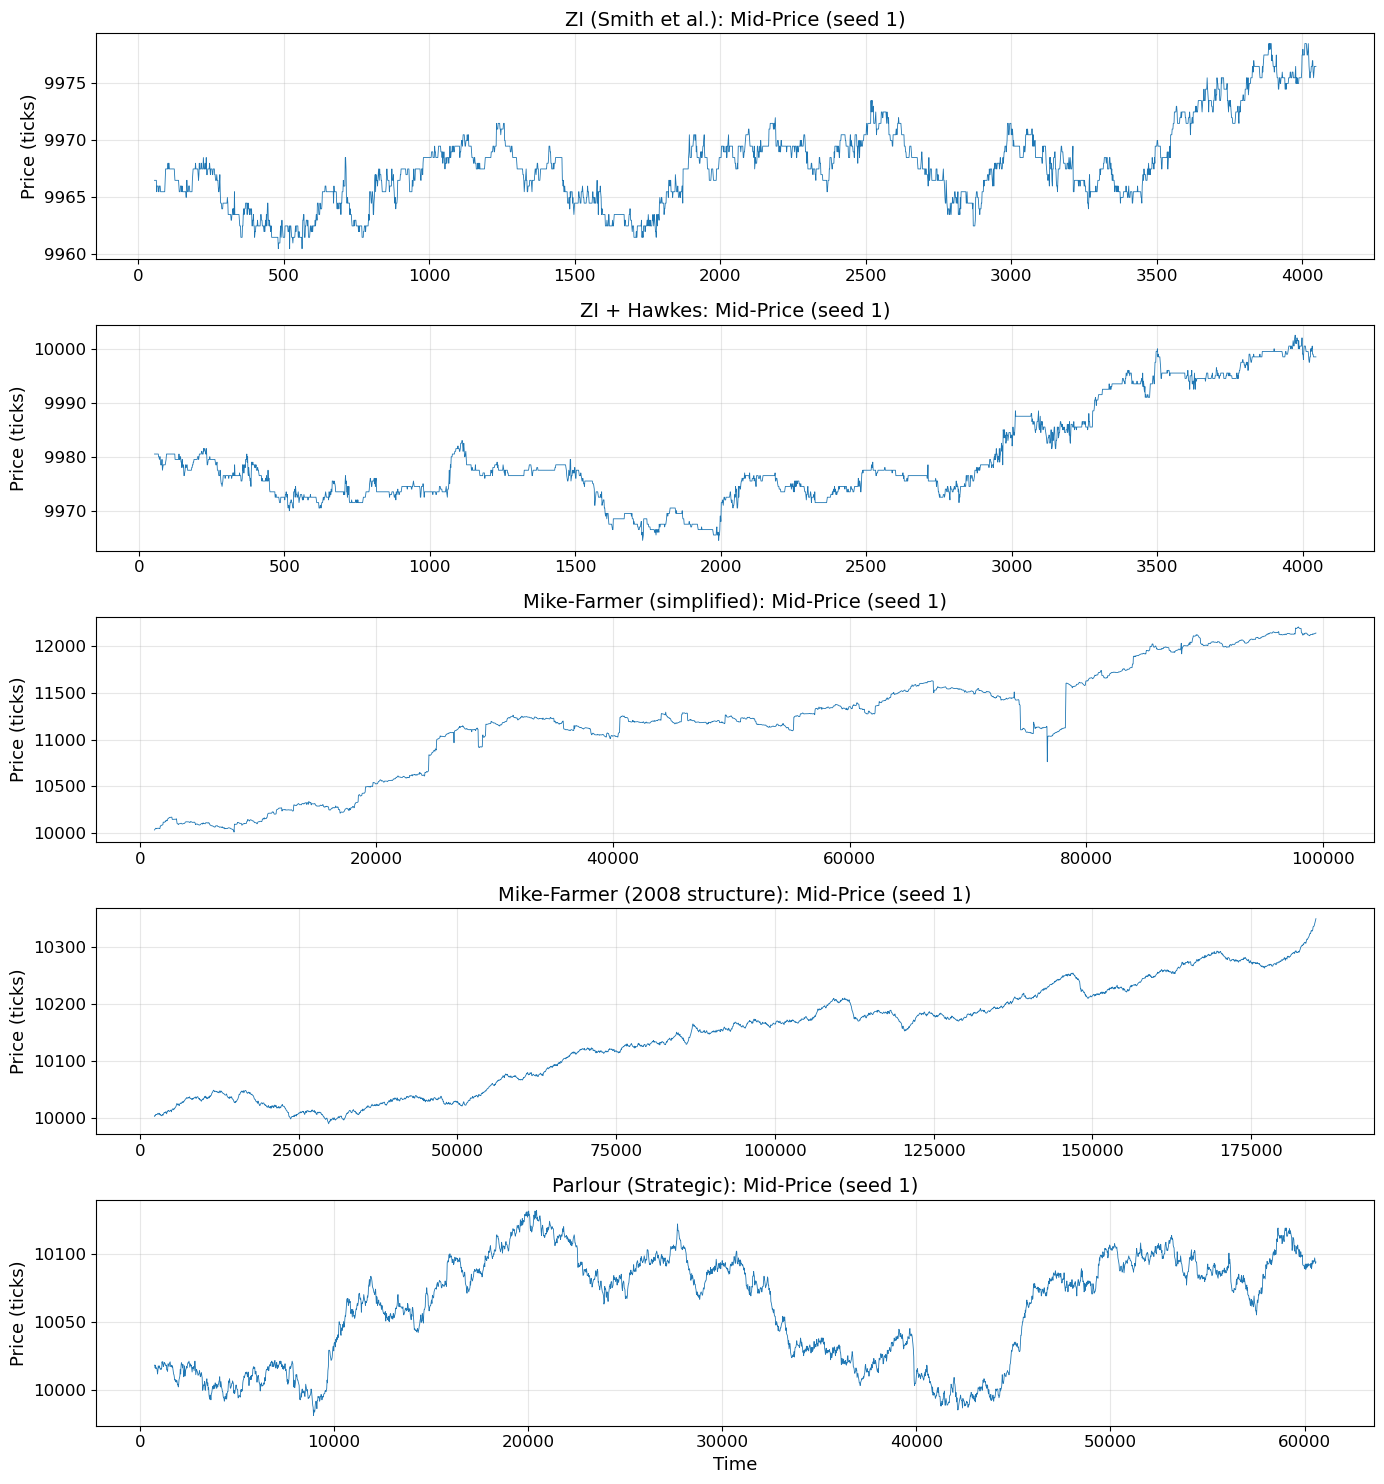

In [3]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(14, 3 * len(MODELS)))
for ax, (name, runs) in zip(axes, results.items(), strict=True):
    times, mids = runs[0]['price_path']
    ax.plot(times, mids, linewidth=0.6)
    ax.set_title(f'{name}: Mid-Price (seed {SEEDS[0]})')
    ax.set_ylabel('Price (ticks)')
axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

## 3. Returns and Volatility

The top row shows each model's return distribution (first seed) on a log scale against a fitted normal curve; the bottom row shows the autocorrelation of the ranks of $|r|$, a volatility-clustering measure that a few extreme returns cannot dominate.

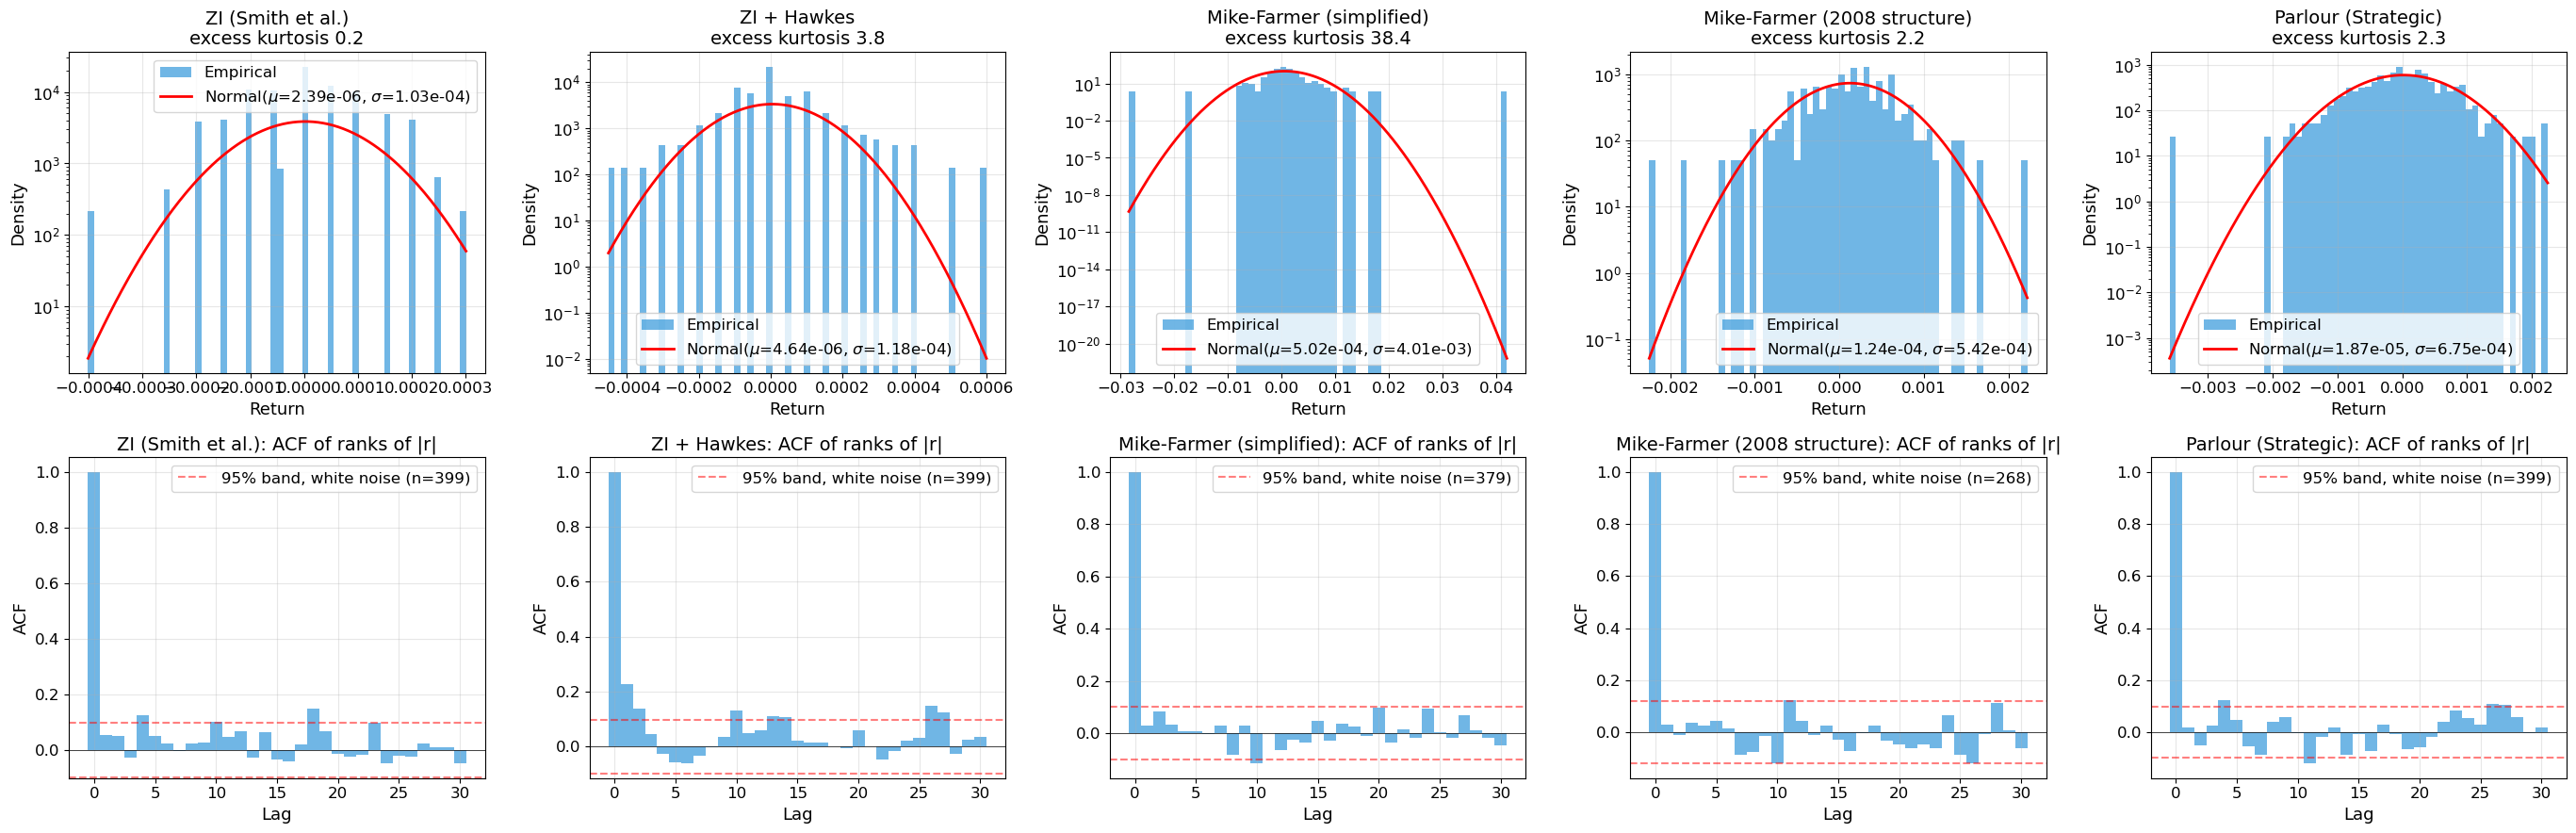

In [4]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(5.5 * len(MODELS), 9))
for j, (name, runs) in enumerate(results.items()):
    r = runs[0]['returns']
    plot_return_distribution(r, n_bins=60, ax=axes[0, j])
    axes[0, j].set_title(f'{name}\nexcess kurtosis {stats.kurtosis(r):.1f}')
    plot_acf(compute_rank_volatility_acf(r, 30), title=f'{name}: ACF of ranks of |r|', ax=axes[1, j], n=len(r))
plt.tight_layout()
plt.show()

## 4. Scorecard

Each statistic is averaged over the 32 seeds; each cell shows that mean and its 95% confidence interval across seeds. Verdicts use the standard error (SE) of the mean. With seven facts and five models we make 35 comparisons, so a result two standard errors from its threshold can easily be chance. We therefore grade the evidence:

- **Yes**: the mean clears the threshold, in the stated direction, by more than 3 SE.
- **Weak evidence**: it clears it by 2–3 SE.
- **No**: it misses a materiality threshold (kurtosis, clustering, impact slope) by more than 2 SE.
- **Inconclusive** (threshold rows) or **Not detected** (effects that should be absent without the mechanism): anything else.

| Stylized fact | Measurement | "Yes" means |
|---|---|---|
| Heavy-tailed returns | Excess kurtosis of $K$-event log returns | above 1 |
| Volatility clustering | Lag-1 autocorrelation of the ranks of $\lvert r\rvert$ | above 0.1 |
| Long memory in order signs | Autocorrelation of buy/sell signs at lag 100 | above 0 |
| Bid-ask bounce | Lag-1 autocorrelation of trade-price changes | below 0 |
| Hump-shaped depth profile | Mean depth profile, classified as in Notebook 04 | hump |
| Concave price impact | Log-log slope of mean virtual impact (Notebook 04) | below 0.95 |

The kurtosis and clustering rows use materiality thresholds rather than zero. The book's own state changes slowly, so a small positive autocorrelation of $|r|$ can arise mechanically. Real markets show far stronger clustering that persists for weeks (Section 4.7.2), so the clustering row asks for at least 0.1.

Power-law relative prices are an input to the Mike-Farmer models rather than something they produce, so that row records how each model places orders.

A verdict can stay open for two reasons: too few seeds, or a value that sits close to its bar. Below the table, each open threshold verdict lists how many seeds it would take to settle at the current estimate.

In [5]:
def mean_se(values):
    values = np.asarray(values, dtype=float)
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))


def ci95(values):
    """95% confidence interval for the mean across seeds (Student's t)."""
    mean, se = mean_se(values)
    half = stats.t.ppf(0.975, len(values) - 1) * se
    return mean - half, mean + half


def grade(margin, se, otherwise):
    """'Yes' beyond 3 SE, 'Weak evidence' at 2-3 SE, else the given fallback."""
    if margin > 3 * se:
        return 'Yes'
    if margin > 2 * se:
        return 'Weak evidence'
    return otherwise


def describe(call, values):
    lo, hi = ci95(values)
    return f"{call} ({np.mean(values):.3g}; 95% CI {lo:.3g} to {hi:.3g})"


open_verdicts = []  # threshold verdicts not settled, explained after the table


def threshold_verdict(values, threshold, above=True, where=None):
    mean, se = mean_se(values)
    margin = mean - threshold if above else threshold - mean  # positive on the "Yes" side
    call = grade(margin, se, 'No' if margin < -2 * se else 'Inconclusive')
    if call in ('Inconclusive', 'Weak evidence') and where is not None:
        open_verdicts.append((*where, values, threshold, margin))
    return describe(call, values)


def effect_verdict(values, positive=True):
    mean, se = mean_se(values)
    return describe(grade(mean if positive else -mean, se, 'Not detected'), values)


def hump_verdict(runs):
    profile = np.mean([r['depth_profile'] for r in runs], axis=0)
    shape, rise, fall, peak = classify_depth_profile(profile)
    if shape == 'hump':
        return f"Yes (peak {peak} tick{'s' if peak != 1 else ''} out, {rise:+.0%} above the best quote)"
    return 'No (rises to a plateau)' if shape == 'plateau' else 'No (deepest at the best quote)'


def impact_verdict(name, runs):
    covered = min(len(r['impact_sizes']) for r in runs)
    if covered < 5:
        return f"Not measurable (90% of snapshots absorb only {covered} lot{'s' if covered != 1 else ''})"
    slopes = [fit_loglog_slope(r['impact_sizes'], r['impact']) for r in runs]
    return threshold_verdict(slopes, 0.95, above=False, where=(name, 'Concave price impact'))


placement = {
    'ZI (Smith et al.)': 'No (uniform placement)',
    'ZI + Hawkes': 'No (uniform placement)',
    'Mike-Farmer (simplified)': 'Yes (built in)',
    'Mike-Farmer (2008 structure)': "Yes (built in: Student's t)",
    'Parlour (Strategic)': 'No (geometric placement)',
}

scorecard = pd.DataFrame({
    name: {
        'Mean spread (ticks)': f"{mean_se([r['mean_spread'] for r in runs])[0]:.2f}",
        'Heavy-tailed returns': threshold_verdict([r['kurtosis'] for r in runs], 1.0,
                                                  where=(name, 'Heavy-tailed returns')),
        'Volatility clustering': threshold_verdict([r['rank_acf_lag1'] for r in runs], 0.1,
                                                   where=(name, 'Volatility clustering')),
        'Long memory in order signs': effect_verdict([r['sign_acf_lag100'] for r in runs]),
        'Bid-ask bounce': effect_verdict([r['bounce_acf_lag1'] for r in runs], positive=False),
        'Hump-shaped depth profile': hump_verdict(runs),
        'Concave price impact': impact_verdict(name, runs),
        'Power-law relative prices': placement[name],
    }
    for name, runs in results.items()
})
display(scorecard)

,ZI (Smith et al.),ZI + Hawkes,Mike-Farmer (simplified),Mike-Farmer (2008 structure),Parlour (Strategic)
Mean spread (ticks),1.32,1.34,2.50,2.15,2.20
Heavy-tailed returns,No (0.335; 95% CI 0.214 to 0.456),Yes (5.26; 95% CI 4.27 to 6.26),Yes (60.8; 95% CI 39.6 to 81.9),Yes (25; 95% CI 10.1 to 39.9),Inconclusive (0.951; 95% CI 0.685 to 1.22)
Volatility clustering,No (0.0512; 95% CI 0.0324 to 0.07),Yes (0.238; 95% CI 0.217 to 0.259),No (0.0242; 95% CI 0.00629 to 0.0422),Inconclusive (0.099; 95% CI 0.0745 to 0.123),No (0.00189; 95% CI -0.0101 to 0.0138)
Long memory in order signs,Not detected (0.000562; 95% CI -0.000178 to 0.0013),Not detected (0.00033; 95% CI -0.000563 to 0.00122),Yes (0.00757; 95% CI 0.00697 to 0.00817),Yes (0.0205; 95% CI 0.0193 to 0.0217),Not detected (-0.000535; 95% CI -0.00116 to 8.88e-05)
Bid-ask bounce,Yes (-0.428; 95% CI -0.433 to -0.424),Yes (-0.429; 95% CI -0.435 to -0.423),Yes (-0.344; 95% CI -0.385 to -0.304),Yes (-0.402; 95% CI -0.408 to -0.396),Yes (-0.423; 95% CI -0.424 to -0.422)
Hump-shaped depth profile,No (rises to a plateau),No (rises to a plateau),No (deepest at the best quote),"Yes (peak 3 ticks out, +91% above the best quote)","Yes (peak 2 ticks out, +11% above the best quote)"
Concave price impact,Yes (0.896; 95% CI 0.893 to 0.899),Yes (0.919; 95% CI 0.913 to 0.926),Not measurable (90% of snapshots absorb only 2 lots),Yes (0.863; 95% CI 0.851 to 0.874),Yes (0.873; 95% CI 0.867 to 0.879)
Power-law relative prices,No (uniform placement),No (uniform placement),Yes (built in),Yes (built in: Student's t),No (geometric placement)


In [6]:
# Open verdicts: how many seeds would settle each one at its current estimate
# ("Yes" needs a margin of 3 SE above the bar, "No" 2 SE below it).
if not open_verdicts:
    print("Every threshold verdict is settled.")
for name, fact, values, bar, margin in open_verdicts:
    lo, hi = ci95(values)
    estimate = f"{np.mean(values):.3g} (95% CI {lo:.3g} to {hi:.3g}) against a bar of {bar:g}"
    k = 3 if margin > 0 else 2
    needed = (k * np.std(values, ddof=1) / abs(margin)) ** 2 if margin else np.inf
    if needed > 10_000:
        print(f"{name}, {fact.lower()}: {estimate}. It sits on the bar; more seeds would not settle it.")
    elif needed <= 4 * len(values):
        print(f"{name}, {fact.lower()}: {estimate}. About {np.ceil(needed):.0f} seeds would likely settle it.")
    else:
        print(f"{name}, {fact.lower()}: {estimate}. Settling it would take about {np.ceil(needed):,.0f} seeds "
              f"({needed / len(values):.0f}x the {len(values)} used here): the value sits close to the bar.")

Mike-Farmer (2008 structure), volatility clustering: 0.099 (95% CI 0.0745 to 0.123) against a bar of 0.1. It sits on the bar; more seeds would not settle it.
Parlour (Strategic), heavy-tailed returns: 0.951 (95% CI 0.685 to 1.22) against a bar of 1. Settling it would take about 915 seeds (29x the 32 used here): the value sits close to the bar.


## 5. The Feedback Loop (Parlour Model)

The Parlour-inspired rule makes traders condition on the book: the probability of a market order rises when the spread is narrow (a limit order offers little price improvement) and when the queue at the best quotes is long (a new limit order would wait a long time). We evaluate that probability on books with a chosen spread and depth.

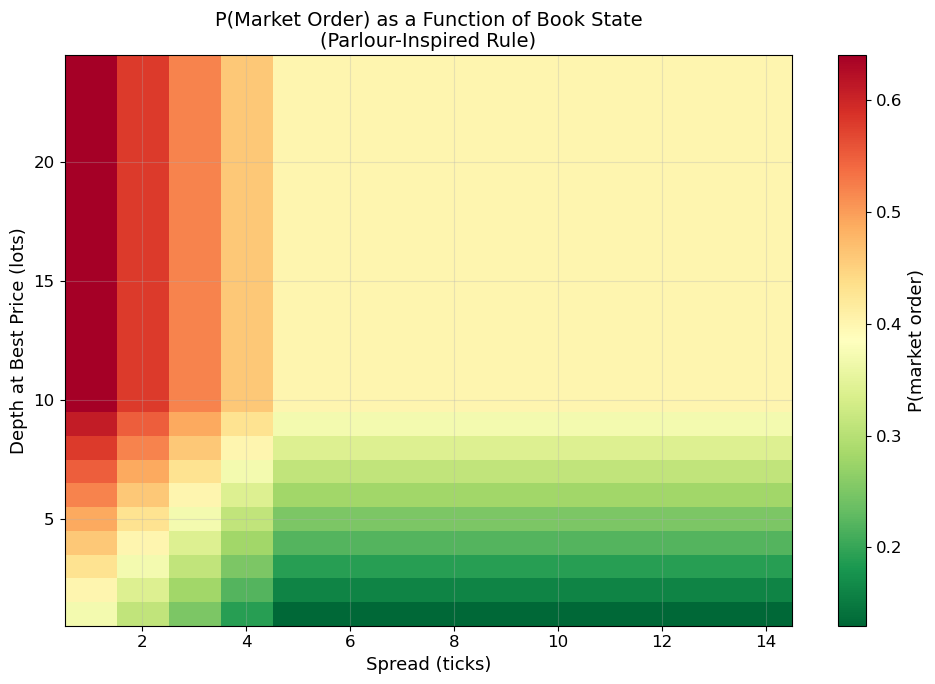

P(market order): spread 1, depth 24 -> 0.64; spread 14, depth 1 -> 0.13
Narrow spreads and long queues push traders toward market orders, which consume the queue and widen the spread, which in turn favors limit orders: the book state and the order flow feed back on each other.


In [7]:
pm = ParlourModel()
spreads_range = np.arange(1, 15)
depths_range = np.arange(1, 25)

prob_grid = np.zeros((len(depths_range), len(spreads_range)))
for i, depth in enumerate(depths_range):
    for j, spread in enumerate(spreads_range):
        reset_order_id_counter()
        book = OrderBook()
        for _ in range(depth):
            book.add_order(limit_order(10000, 1, 0.0, Side.BID))
            book.add_order(limit_order(10000 + spread, 1, 0.0, Side.ASK))
        prob_grid[i, j] = pm._prob_market_order(book)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(prob_grid, aspect='auto', origin='lower', cmap='RdYlGn_r',
               extent=[0.5, spreads_range[-1] + 0.5, 0.5, depths_range[-1] + 0.5])
ax.set_xlabel('Spread (ticks)')
ax.set_ylabel('Depth at Best Price (lots)')
ax.set_title('P(Market Order) as a Function of Book State\n(Parlour-Inspired Rule)')
plt.colorbar(im, label='P(market order)')
plt.tight_layout()
plt.show()

narrow_deep, wide_shallow = prob_grid[-1, 0], prob_grid[0, -1]
print(f"P(market order): spread 1, depth {depths_range[-1]} -> {narrow_deep:.2f}; "
      f"spread {spreads_range[-1]}, depth 1 -> {wide_shallow:.2f}")
if narrow_deep > wide_shallow:
    print("Narrow spreads and long queues push traders toward market orders, which consume the queue and "
          "widen the spread, which in turn favors limit orders: the book state and the order flow feed back "
          "on each other.")

## Summary

The models start from different premises: pure chance (ZI), chance with clustered market orders (ZI + Hawkes), empirically calibrated order flow (the two Mike-Farmer variants), and a rule of thumb for traders who condition on the book (Parlour). The tally below counts the stylized facts each one reproduces in these runs.

In [8]:
facts = [row for row in scorecard.index if row != 'Mean spread (ticks)']
for name in scorecard.columns:
    reproduced = [fact for fact in facts if scorecard.loc[fact, name].startswith('Yes')]
    weak = [fact for fact in facts if scorecard.loc[fact, name].startswith('Weak')]
    line = f"{name:28s} {len(reproduced)} of {len(facts)}: {', '.join(reproduced) if reproduced else 'none'}"
    if weak:
        line += f" (weak evidence: {', '.join(weak)})"
    print(line)

complete = [name for name in scorecard.columns
            if all(scorecard.loc[fact, name].startswith('Yes') for fact in facts)]
print("\nModels that reproduce every fact in the scorecard:", ', '.join(complete) if complete else 'none')

ZI (Smith et al.)            2 of 7: Bid-ask bounce, Concave price impact
ZI + Hawkes                  4 of 7: Heavy-tailed returns, Volatility clustering, Bid-ask bounce, Concave price impact
Mike-Farmer (simplified)     4 of 7: Heavy-tailed returns, Long memory in order signs, Bid-ask bounce, Power-law relative prices
Mike-Farmer (2008 structure) 6 of 7: Heavy-tailed returns, Long memory in order signs, Bid-ask bounce, Hump-shaped depth profile, Concave price impact, Power-law relative prices
Parlour (Strategic)          3 of 7: Bid-ask bounce, Hump-shaped depth profile, Concave price impact

Models that reproduce every fact in the scorecard: none


As the paper puts it when introducing LOB models in Section 5: *"Unsurprisingly, there is no clear consensus on the best approach."*

**Next:** Notebook 06 explores the open problems from Section 6.